# 04 — Multimodal Text & Image Fusion

Goal: Combine state-of-the-art text (TF-IDF + SVM, CamemBERT) and image models (ConvNeXt-Tiny) to maximise classification performance.

- **Image Model**: `ConvNeXt-Tiny` (Full Fine-Tuning + Smart Cropping from `notebooks/03_image_fineTuning/03_7_image_convnext_optimized.ipynb`), reaching **0.6998 Weighted F1** alone.
- **Text Models**: Calibrated `LinearSVC` (**0.8430 Weighted F1**) and fine-tuned `CamemBERT` (**0.8765 Weighted F1**).
- **Fusion Strategies**:
  1. **Simple Soft Voting**: Weighted probability average between SVM and ConvNeXt-Tiny.
  2. **Stacking Classifier (Random Forest)**: Meta-classifier trained via 5-fold cross-validation on the combined 81-dimensional probability representations (27 classes × 3 models).


## 1. Text probabilities

We use the optimised text model from notebook 04 (all features, binary TF-IDF, LinearSVC with C = 1). A LinearSVC gives scores, not probabilities. Calibration learns on the training set (3-fold CV) how to turn these scores into probabilities.

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold
from sklearn.svm import LinearSVC

# Resolve repository root directory
PROJECT_ROOT             = Path.cwd().resolve()
while PROJECT_ROOT.name in {"notebooks"}:
    PROJECT_ROOT         = PROJECT_ROOT.parent

from src.categories import CATEGORY_NAMES
from src.metrics import compute_per_class_metrics

DATA_PATH                = PROJECT_ROOT / "data" / "processed" / "text_train_processed.csv"
TEXT_PROBS_OUT           = PROJECT_ROOT / "data" / "processed" / "text_validation_probabilities.csv"
IMAGE_PREDS_PATH         = PROJECT_ROOT / "models" / "outputs" / "03_7_convnext_tiny_optimized_validation_predictions.csv"
CAMEMBERT_PROBS_PATH     = PROJECT_ROOT / "data" / "processed" / "camembert_validation_probabilities.csv"

RANDOM_STATE             = 42
CV_FOLDS                 = 5

data                     = pd.read_csv(DATA_PATH)
train                    = data[data["split"] == "train"]
validation               = data[data["split"] == "validation"]

vectorizer               = TfidfVectorizer(ngram_range=(1, 2), min_df=2, binary=True)
X_train                  = vectorizer.fit_transform(train["text_combined"])
X_validation             = vectorizer.transform(validation["text_combined"])

# Calibrated LinearSVC from notebook 03_2 (outputs well-calibrated class probabilities)
text_model               = CalibratedClassifierCV(LinearSVC(C=1, random_state=RANDOM_STATE), cv=3)
text_model.fit(X_train, train["prdtypecode"])
classes                  = text_model.classes_

text_probs               = pd.DataFrame(text_model.predict_proba(X_validation), columns=classes)
text_probs.insert(0, "row_id", validation["row_id"].to_numpy())
text_probs.to_csv(TEXT_PROBS_OUT, index=False)

print(f"Text probabilities saved: {text_probs.shape}")
print(f"Each row sums to 1      : {np.allclose(text_probs[classes].sum(axis=1), 1)}")


Text probabilities saved: (16984, 28)
Each row sums to 1: True


## 2. Match text and image on the same products

In [2]:
# Best image model: ConvNeXt-Tiny (03_7_image_convnext_optimized)
image                    = pd.read_csv(IMAGE_PREDS_PATH)
image.columns            = [c.strip() for c in image.columns]
image_probs              = image[["row_id"] + [f"prob_{c}" for c in classes]]
image_probs.columns      = ["row_id"] + list(classes)

both                     = (
    validation[["row_id", "prdtypecode"]]
    .merge(text_probs,  on="row_id")
    .merge(image_probs, on="row_id", suffixes=("_text", "_image"))
)
y_true                   = both["prdtypecode"].to_numpy()
P_text                   = both[[f"{c}_text" for c in classes]].to_numpy()
P_image                  = both[[f"{c}_image" for c in classes]].to_numpy()

print(f"Products scored by both: {len(both):,}")


Products scored by both: 16984


## 3. Combine the models

Text and image probabilities exist for the 16984 validation products, which none of the models were trained on. We score every method with 5-fold cross-validation on these products: the combiner learns on 4/5 of them and predicts the remaining 1/5. Every product is predicted by a combiner that never saw it.

For simple fusion, the text weight (0 to 1, in steps of 0.1) is chosen on the 4/5 part only, in the same way.

Text weight chosen in each fold: [0.6, 0.6, 0.6, 0.6, 0.6]


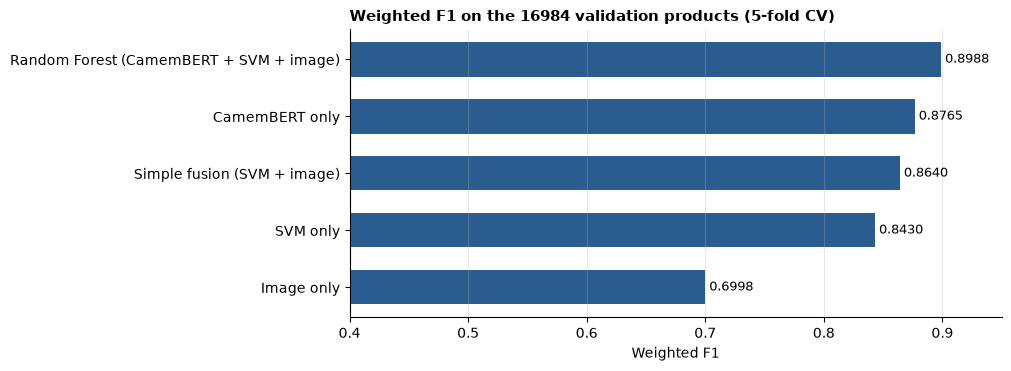

Model,Weighted F1,Macro F1
Random Forest (CamemBERT + SVM + image),0.8988,0.8856
CamemBERT only,0.8765,0.8594
Simple fusion (SVM + image),0.8640,0.8548
SVM only,0.8430,0.8326
Image only,0.6998,0.6752


In [3]:
camembert                = pd.read_csv(CAMEMBERT_PROBS_PATH)
P_camembert              = both[["row_id"]].merge(camembert, on="row_id")[[str(c) for c in classes]].to_numpy()

X_all                    = np.hstack([P_camembert, P_text, P_image])
folds                    = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
weights                  = np.round(np.arange(0, 1.01, 0.1), 1)

predictions              = {
    "Image only (ConvNeXt-Tiny)"            : classes[P_image.argmax(axis=1)],
    "SVM only (TF-IDF)"                     : classes[P_text.argmax(axis=1)],
    "CamemBERT only"                         : classes[P_camembert.argmax(axis=1)],
    "Simple fusion (SVM + image)"           : np.zeros_like(y_true),
    "Random Forest (CamemBERT + SVM + image)": np.zeros_like(y_true),
}
chosen_weights           = []

for train_idx, test_idx in folds.split(X_all, y_true):
    fold_scores          = [
        f1_score(y_true[train_idx], classes[(w * P_text[train_idx] + (1 - w) * P_image[train_idx]).argmax(axis=1)], average="weighted")
        for w in weights
    ]
    best_w               = weights[int(np.argmax(fold_scores))]
    chosen_weights.append(float(best_w))
    predictions["Simple fusion (SVM + image)"][test_idx] = classes[(best_w * P_text[test_idx] + (1 - best_w) * P_image[test_idx]).argmax(axis=1)]

    forest               = RandomForestClassifier(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=RANDOM_STATE)
    predictions["Random Forest (CamemBERT + SVM + image)"][test_idx] = forest.fit(X_all[train_idx], y_true[train_idx]).predict(X_all[test_idx])

print(f"Text weight chosen in each fold: {chosen_weights}")
results                  = pd.DataFrame({
    "Model":       list(predictions),
    "Weighted F1": [f1_score(y_true, p, average="weighted") for p in predictions.values()],
    "Macro F1":    [f1_score(y_true, p, average="macro")    for p in predictions.values()],
})

fig, ax                  = plt.subplots(figsize=(10, 3.6), constrained_layout=True)
ordered                  = results.sort_values("Weighted F1")
bars                     = ax.barh(ordered["Model"], ordered["Weighted F1"], color="#2b5c8f", height=0.6)
ax.bar_label(bars, labels=[f"{v:.4f}" for v in ordered["Weighted F1"]], padding=3, fontsize=9)
ax.set_xlim(0.4, 0.95)
ax.set_title("Weighted F1 on the 16,984 validation products (5-fold CV)", loc="left", fontsize=11, fontweight="bold")
ax.set_xlabel("Weighted F1")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", alpha=0.3)
plt.show()

display(results.sort_values("Weighted F1", ascending=False).style.hide(axis="index").format(precision=4))


### Analysis

- The best model is the Random Forest on CamemBERT, SVM and image: 0.8988 weighted F1 and 0.8856 macro F1.
- That is +2.2 points over CamemBERT alone (0.8765) and +5.6 points over the SVM alone (0.8430).
- Simple fusion with one fixed weight (60% SVM, 40% image) reaches 0.8640: images help, but a fixed weight cannot use them as well.
- We also tried Gradient Boosting instead of Random Forest. It scored slightly lower and was much slower, so we kept the Random Forest.

## 4. Per category: best fusion vs CamemBERT

In [4]:
best                     = "Random Forest (CamemBERT + SVM + image)"
camembert_scores         = compute_per_class_metrics(y_true, predictions["CamemBERT only"], classes)
best_scores              = compute_per_class_metrics(y_true, predictions[best], classes)

per_class                = pd.DataFrame({
    "Code":           classes,
    "Category":       [CATEGORY_NAMES[c] for c in classes],
    "CamemBERT F1":   camembert_scores["f1"],
    "Best fusion F1": best_scores["f1"],
})
per_class["Gain"]        = per_class["Best fusion F1"] - per_class["CamemBERT F1"]
display(per_class.sort_values("Gain", ascending=False).style.hide(axis="index").format(precision=3))


Code,Category,CamemBERT F1,Best fusion F1,Gain
2705,New Books,0.818,0.926,0.108
10,Used Books,0.689,0.788,0.099
1180,Wargames,0.614,0.706,0.093
40,Games,0.795,0.855,0.059
1302,Outdoor Toys,0.810,0.853,0.043
1140,Figurines,0.834,0.862,0.028
60,Consoles,0.876,0.903,0.027
1940,Food,0.946,0.969,0.023
1160,Cards,0.955,0.978,0.023
1320,Baby,0.856,0.877,0.021


### Analysis

- The best fusion is better than CamemBERT on 26 of the 27 categories. Only Baby Socks drops slightly (-0.3 points).
- The largest gains are on New Books (+10.8 points), Used Books (+9.9) and Wargames (+9.3).
- Books gain the most from the image: the cover shows if a book is new, used, or a lot of several books.
- Wargames was CamemBERT's weakest category. The SVM catches its rare exact words (*warhammer*, *heroclix*), so combining both fixes it.

## Conclusion

- Combining models helps, and a learned combination (Random Forest) works better than a fixed weight.
- Best model: Random Forest on the CamemBERT, SVM and ConvNeXt probabilities, with 0.8988 weighted F1 on the validation products (5-fold CV).
- Each part adds something: CamemBERT reads context, the SVM catches rare specific words, and the image helps on books.